In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load the Dataset
house= pd.read_csv("House_Rent_Dataset.csv")
house.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [5]:
house.tail()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent
4745,2022-05-04,2,15000,1000,4 out of 5,Carpet Area,Suchitra Circle,Hyderabad,Unfurnished,Bachelors,2,Contact Owner


In [6]:
house.sample(4)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
2907,2022-06-24,1,11000,450,3 out of 4,Super Area,"Manak Vihar, Anand Vihar",Delhi,Semi-Furnished,Bachelors,1,Contact Owner
273,2022-04-27,1,6000,130,Ground out of 2,Carpet Area,Bow Bazar,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
1046,2022-04-29,3,40000,1200,2 out of 4,Super Area,Kandivali West,Mumbai,Semi-Furnished,Family,2,Contact Owner
367,2022-06-11,2,8000,900,Ground out of 1,Super Area,"Teghoria, Baguiati",Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner


In [7]:
house.isna().sum()

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [8]:
dup=house.duplicated().sum()
print(dup)

0


In [9]:
house.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='str')

In [10]:
house=house.drop(['Posted On','Floor','Area Locality'],axis=1)

In [11]:
house.columns

Index(['BHK', 'Rent', 'Size', 'Area Type', 'City', 'Furnishing Status',
       'Tenant Preferred', 'Bathroom', 'Point of Contact'],
      dtype='str')

In [12]:
house.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   BHK                4746 non-null   int64
 1   Rent               4746 non-null   int64
 2   Size               4746 non-null   int64
 3   Area Type          4746 non-null   str  
 4   City               4746 non-null   str  
 5   Furnishing Status  4746 non-null   str  
 6   Tenant Preferred   4746 non-null   str  
 7   Bathroom           4746 non-null   int64
 8   Point of Contact   4746 non-null   str  
dtypes: int64(4), str(5)
memory usage: 333.8 KB


<Axes: xlabel='Rent', ylabel='Size'>

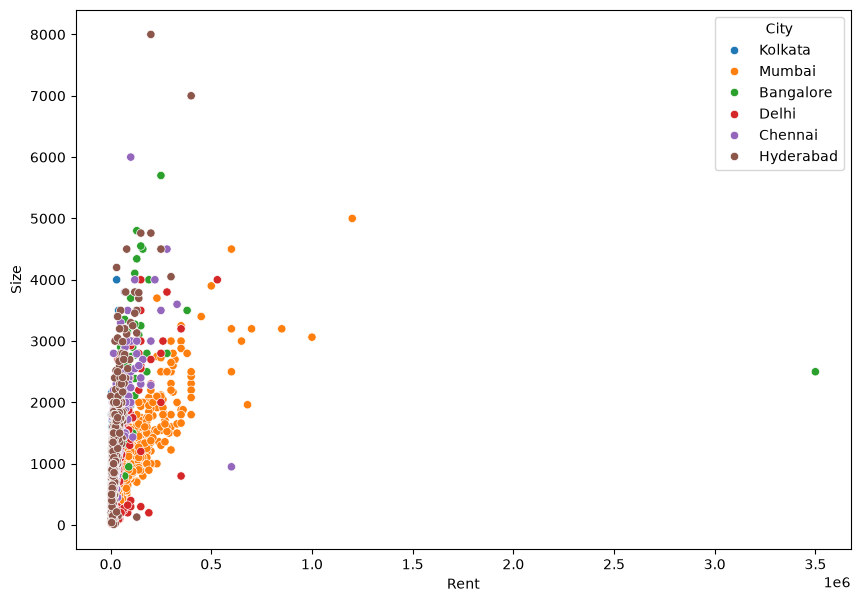

In [13]:
plt.figure(figsize=(10,7))
sns.scatterplot(data=house,x='Rent',y='Size',hue='City')

In [18]:
%pip install xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ------- -------------------------------- 9.4/48.9 MB 55.2 MB/s eta 0:00:01
   ----------------------- ---------------- 28.6/48.9 MB 75.1 MB/s eta 0:00:01
   ---------------------------------------  48.5/48.9 MB 82.4 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 68.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

In [29]:
import sys
!{sys.executable} -m pip install xgboost



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
dt=model=DecisionTreeRegressor()
rf_model= RandomForestRegressor(n_estimators=50)
svr_model=SVR()
xgb_model=xgb.XGBRegressor(objective='reg:squderr')

In [22]:
#prediction
y_dt=dt_model.predict(x_test)
y_rf=rf_model.predict(x_test)
y_svr=svr_model.predict(x_test)
y_xgb=xgb_model.predict(x_test)

NameError: name 'dt_model' is not defined

In [32]:
# ==========================================
# 1. INSTALL XGBOOST
# ==========================================

%pip install xgboost


# ==========================================
# 2. IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb


# ==========================================
# 3. LOAD DATASET
# ==========================================

house = pd.read_csv("House_Rent_Dataset.csv")

print("Dataset loaded!")
print(house.shape)


# ==========================================
# 4. SELECT FEATURES AND TARGET
# ==========================================

y = house['Rent']

X = house.drop('Rent', axis=1)


# ==========================================
# 5. SELECT NUMERICAL COLUMNS
# ==========================================

numeric_features = [
    'BHK',
    'Size',
    'Bathroom'
]


# ==========================================
# 6. SELECT CATEGORICAL COLUMNS
# ==========================================

categorical_features = [
    'Area Type',
    'City',
    'Furnishing Status',
    'Tenant Preferred',
    'Point of Contact'
]


# ==========================================
# 7. PREPROCESSING
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)


# ==========================================
# 8. TRAIN-TEST SPLIT
# ==========================================

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)


# ==========================================
# 9. CREATE MODELS
# ==========================================

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        random_state=42
    ))
])


rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=50,
        random_state=42
    ))
])


svr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVR())
])


xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=50,
        random_state=42
    ))
])


# ==========================================
# 10. TRAIN ALL 4 MODELS
# ==========================================

print("\nTraining models...")

dt_model.fit(x_train, y_train)
print("Decision Tree trained")

rf_model.fit(x_train, y_train)
print("Random Forest trained")

svr_model.fit(x_train, y_train)
print("SVR trained")

xgb_model.fit(x_train, y_train)
print("XGBoost trained")


# ==========================================
# 11. PREDICTION
# ==========================================

y_dt = dt_model.predict(x_test)
y_rf = rf_model.predict(x_test)
y_svr = svr_model.predict(x_test)
y_xgb = xgb_model.predict(x_test)

print("\nPredictions completed!")


# ==========================================
# 12. EVALUATION
# ==========================================

models = {
    "Decision Tree": y_dt,
    "Random Forest": y_rf,
    "SVR": y_svr,
    "XGBoost": y_xgb
}

results = []

for name, y_pred in models.items():

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })


# ==========================================
# 13. RESULTS
# ==========================================

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE")
print("=" * 70)

print(results_df.to_string(index=False))


# ==========================================
# 14. BEST MODEL
# ==========================================

best_model = results_df.loc[
    results_df['R2 Score'].idxmax()
]

print("\nBEST MODEL")
print("=" * 70)
print(best_model)



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Dataset loaded!
(4746, 12)
Training data: (3796, 11)
Testing data : (950, 11)

Training models...
Decision Tree trained
Random Forest trained
SVR trained
XGBoost trained

Predictions completed!

MODEL PERFORMANCE
        Model          MAE          MSE          RMSE  R2 Score
Decision Tree 15493.073646 2.172197e+09  46606.835178  0.454959
Random Forest 14114.356094 1.823770e+09  42705.622021  0.542385
          SVR 24161.869573 4.313048e+09  65673.801015 -0.082217
      XGBoost 16503.955078 1.325200e+10 115117.325890 -2.325152

BEST MODEL
Model           Random Forest
MAE              14114.356094
MSE         1823770152.169839
RMSE             42705.622021
R2 Score             0.542385
Name: 1, dtype: object


In [34]:
# ==========================================
# 1. INSTALL XGBOOST
# ==========================================

%pip install xgboost


# ==========================================
# 2. IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb


# ==========================================
# 3. LOAD DATASET
# ==========================================

house = pd.read_csv("House_Rent_Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", house.shape)


# ==========================================
# 4. SELECT FEATURES AND TARGET
# ==========================================

# Target
y = house['Rent']

# Features
X = house[
    [
        'BHK',
        'Size',
        'Area Type',
        'City',
        'Furnishing Status',
        'Tenant Preferred',
        'Bathroom',
        'Point of Contact'
    ]
]


# ==========================================
# 5. NUMERICAL FEATURES
# ==========================================

numeric_features = [
    'BHK',
    'Size',
    'Bathroom'
]


# ==========================================
# 6. CATEGORICAL FEATURES
# ==========================================

categorical_features = [
    'Area Type',
    'City',
    'Furnishing Status',
    'Tenant Preferred',
    'Point of Contact'
]


# ==========================================
# 7. PREPROCESSING
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            'passthrough',
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)


# ==========================================
# 8. TRAIN-TEST SPLIT
# ==========================================

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(x_train))
print("Testing samples :", len(x_test))


# ==========================================
# 9. CREATE DECISION TREE
# ==========================================

dt_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        DecisionTreeRegressor(
            random_state=42
        )
    )
])


# ==========================================
# 10. CREATE RANDOM FOREST
# ==========================================

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        RandomForestRegressor(
            n_estimators=50,
            random_state=42
        )
    )
])


# ==========================================
# 11. CREATE SVR
# ==========================================

svr_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        SVR()
    )
])


# ==========================================
# 12. CREATE XGBOOST
# ==========================================

xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    (
        'model',
        xgb.XGBRegressor(
            objective='reg:squarederror',
            n_estimators=50,
            random_state=42
        )
    )
])


# ==========================================
# 13. TRAIN ALL 4 MODELS
# ==========================================

print("\nTraining models...")

dt_model.fit(x_train, y_train)
print("✓ Decision Tree trained")

rf_model.fit(x_train, y_train)
print("✓ Random Forest trained")

svr_model.fit(x_train, y_train)
print("✓ SVR trained")

xgb_model.fit(x_train, y_train)
print("✓ XGBoost trained")


# ==========================================
# 14. MAKE PREDICTIONS
# ==========================================

y_dt = dt_model.predict(x_test)
y_rf = rf_model.predict(x_test)
y_svr = svr_model.predict(x_test)
y_xgb = xgb_model.predict(x_test)

print("\n✓ Predictions completed!")


# ==========================================
# 15. EVALUATE MODELS
# ==========================================

predictions = {
    'Decision Tree': y_dt,
    'Random Forest': y_rf,
    'SVR': y_svr,
    'XGBoost': y_xgb
}

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })


# ==========================================
# 16. DISPLAY RESULTS
# ==========================================

results_df = pd.DataFrame(results)

print("\n")
print("=" * 70)
print("MODEL PERFORMANCE")
print("=" * 70)

print(results_df.to_string(index=False))


# ==========================================
# 17. BEST MODEL
# ==========================================

best = results_df.loc[
    results_df['R2 Score'].idxmax()
]

print("\n")
print("=" * 70)
print("BEST MODEL")
print("=" * 70)

print("Model    :", best['Model'])
print("R2 Score :", round(best['R2 Score'], 4))
print("RMSE     :", round(best['RMSE'], 2))
print("MAE      :", round(best['MAE'], 2))



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Dataset loaded successfully!
Shape: (4746, 12)

Training samples: 3796
Testing samples : 950

Training models...
✓ Decision Tree trained
✓ Random Forest trained
✓ SVR trained
✓ XGBoost trained

✓ Predictions completed!


MODEL PERFORMANCE
        Model          MAE          MSE          RMSE  R2 Score
Decision Tree 15493.073646 2.172197e+09  46606.835178  0.454959
Random Forest 14114.356094 1.823770e+09  42705.622021  0.542385
          SVR 24161.869573 4.313048e+09  65673.801015 -0.082217
      XGBoost 16503.955078 1.325200e+10 115117.325890 -2.325152


BEST MODEL
Model    : Random Forest
R2 Score : 0.5424
RMSE     : 42705.62
MAE      : 14114.36


In [35]:
# ==========================================
# PREDICTIONS FROM ALL 4 MODELS
# ==========================================

y_dt = dt_model.predict(x_test)
y_rf = rf_model.predict(x_test)
y_svr = svr_model.predict(x_test)
y_xgb = xgb_model.predict(x_test)


# ==========================================
# PRINT PREDICTIONS
# ==========================================

print("Decision Tree Predictions:")
print(y_dt)

print("\nRandom Forest Predictions:")
print(y_rf)

print("\nSVR Predictions:")
print(y_svr)

print("\nXGBoost Predictions:")
print(y_xgb)


Decision Tree Predictions:
[ 17250.          13000.           8000.          45000.
  55000.          16000.          80000.          12875.
 250000.          12250.           7500.          10000.
  18000.          15000.          22000.          30000.
  85000.           7000.          25000.          28500.
  30000.           7000.          45000.          17500.
 110000.           7500.           8461.53846154  35000.
  10000.          12000.           7461.53846154   8000.
   7000.          12000.          30000.          21000.
   6700.           7270.          13961.53846154   7941.
  13875.         380000.          25000.           6800.
  61400.          10650.          40000.          85000.
 775000.          19750.          10000.          19500.
  10000.          13000.          27000.         140000.
  35000.          50000.          10500.          15000.
  10625.           8461.53846154 120000.          15000.
  20750.          19000.          17000.          30000.
  35

In [36]:
# ==========================================
# ACTUAL VS PREDICTED RENT
# ==========================================

comparison = pd.DataFrame({
    'Actual Rent': y_test.values,
    'Decision Tree': y_dt,
    'Random Forest': y_rf,
    'SVR': y_svr,
    'XGBoost': y_xgb
})

print(comparison.head(10))


   Actual Rent  Decision Tree  Random Forest           SVR        XGBoost
0        16000        17250.0   17226.309524  16063.175200   16171.275391
1        12000        13000.0   13740.356667  15851.251835   15155.475586
2        28000         8000.0   25764.000000  15709.301539   30378.363281
3         8000        45000.0   47640.000000  16339.936297   42012.296875
4        46000        55000.0   72480.000000  16518.813757   81034.515625
5        17000        16000.0   17388.666667  16025.875248   15806.799805
6        57000        80000.0   55203.346667  15753.970078   51620.539062
7         9500        12875.0   12868.615079  15792.292172   12191.451172
8       400000       250000.0  286566.666667  16480.652378  259756.609375
9        15000        12250.0   12542.738095  15766.130301   11200.265625


In [37]:
from sklearn.linear_model import LinearRegression

lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])


In [38]:
lr_model.fit(x_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['BHK','Size','Area Type',...,'Tenant Preferred','Bathroom', 'Point of Contact']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of 

In [39]:
y_lr = lr_model.predict(x_test)


In [40]:
predictions = {
    'Linear Regression': y_lr,
    'Decision Tree': y_dt,
    'Random Forest': y_rf,
    'SVR': y_svr,
    'XGBoost': y_xgb
}


In [41]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb


# ==========================================
# 2. LOAD DATA
# ==========================================

house = pd.read_csv("House_Rent_Dataset.csv")


# ==========================================
# 3. SELECT X AND Y
# ==========================================

y = house['Rent']

X = house[
    [
        'BHK',
        'Size',
        'Area Type',
        'City',
        'Furnishing Status',
        'Tenant Preferred',
        'Bathroom',
        'Point of Contact'
    ]
]


# ==========================================
# 4. DEFINE FEATURES
# ==========================================

numeric_features = [
    'BHK',
    'Size',
    'Bathroom'
]

categorical_features = [
    'Area Type',
    'City',
    'Furnishing Status',
    'Tenant Preferred',
    'Point of Contact'
]


# ==========================================
# 5. PREPROCESSING
# ==========================================

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)


# ==========================================
# 6. TRAIN TEST SPLIT
# ==========================================

x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ==========================================
# 7. CREATE 5 MODELS
# ==========================================

# Linear Regression
lr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])


# Decision Tree
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(
        random_state=42
    ))
])


# Random Forest
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=50,
        random_state=42
    ))
])


# SVR
svr_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVR())
])


# XGBoost
xgb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=50,
        random_state=42
    ))
])


# ==========================================
# 8. TRAIN ALL 5 MODELS
# ==========================================

print("Training models...\n")

lr_model.fit(x_train, y_train)
print("✓ Linear Regression trained")

dt_model.fit(x_train, y_train)
print("✓ Decision Tree trained")

rf_model.fit(x_train, y_train)
print("✓ Random Forest trained")

svr_model.fit(x_train, y_train)
print("✓ SVR trained")

xgb_model.fit(x_train, y_train)
print("✓ XGBoost trained")


# ==========================================
# 9. PREDICTIONS
# ==========================================

y_lr = lr_model.predict(x_test)
y_dt = dt_model.predict(x_test)
y_rf = rf_model.predict(x_test)
y_svr = svr_model.predict(x_test)
y_xgb = xgb_model.predict(x_test)


# ==========================================
# 10. PRINT SOME PREDICTIONS
# ==========================================

print("\nFirst 10 predictions:\n")

comparison = pd.DataFrame({
    'Actual Rent': y_test.values,
    'Linear Regression': y_lr,
    'Decision Tree': y_dt,
    'Random Forest': y_rf,
    'SVR': y_svr,
    'XGBoost': y_xgb
})

print(comparison.head(10))


# ==========================================
# 11. EVALUATE ALL MODELS
# ==========================================

predictions = {
    'Linear Regression': y_lr,
    'Decision Tree': y_dt,
    'Random Forest': y_rf,
    'SVR': y_svr,
    'XGBoost': y_xgb
}

results = []

for name, y_pred in predictions.items():

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })


# ==========================================
# 12. RESULTS TABLE
# ==========================================

results_df = pd.DataFrame(results)

print("\n==========================================")
print("MODEL PERFORMANCE")
print("==========================================")

print(results_df.to_string(index=False))


# ==========================================
# 13. RANK MODELS
# ==========================================

print("\n==========================================")
print("MODELS RANKED BY R2 SCORE")
print("==========================================")

ranked_results = results_df.sort_values(
    by='R2 Score',
    ascending=False
)

print(ranked_results.to_string(index=False))


# ==========================================
# 14. BEST MODEL
# ==========================================

best_model = ranked_results.iloc[0]

print("\n==========================================")
print("BEST MODEL")
print("==========================================")

print("Model    :", best_model['Model'])
print("R2 Score :", round(best_model['R2 Score'], 4))
print("RMSE     :", round(best_model['RMSE'], 2))
print("MAE      :", round(best_model['MAE'], 2))


Training models...

✓ Linear Regression trained
✓ Decision Tree trained
✓ Random Forest trained
✓ SVR trained
✓ XGBoost trained

First 10 predictions:

   Actual Rent  Linear Regression  Decision Tree  Random Forest           SVR  \
0        16000       29357.745151        17250.0   17226.309524  16063.175200   
1        12000       18642.748877        13000.0   13740.356667  15851.251835   
2        28000       60211.059940         8000.0   25764.000000  15709.301539   
3         8000       69398.354240        45000.0   47640.000000  16339.936297   
4        46000       93920.653426        55000.0   72480.000000  16518.813757   
5        17000       22542.165182        16000.0   17388.666667  16025.875248   
6        57000       82900.893642        80000.0   55203.346667  15753.970078   
7         9500       14195.259611        12875.0   12868.615079  15792.292172   
8       400000      181101.906411       250000.0  286566.666667  16480.652378   
9        15000        4536.648176     

In [42]:
# ==========================================
# SAVE RANDOM FOREST MODEL
# ==========================================

import pickle

filename = 'rent_rf_model.pkl'

pickle.dump(rf_model, open(filename, 'wb'))

print("Random Forest model saved successfully!")
print("File name:", filename)


Random Forest model saved successfully!
File name: rent_rf_model.pkl


In [43]:
# ==========================================
# LOAD PICKLE MODEL
# ==========================================

loaded_model = pickle.load(
    open('rent_rf_model.pkl', 'rb')
)

print("Model loaded successfully!")


Model loaded successfully!


In [44]:
# ==========================================
# PREDICT RENT USING SAVED MODEL
# ==========================================

new_house = pd.DataFrame({
    'BHK': [2],
    'Size': [1000],
    'Area Type': ['Super Area'],
    'City': ['Kolkata'],
    'Furnishing Status': ['Semi-Furnished'],
    'Tenant Preferred': ['Bachelors/Family'],
    'Bathroom': [2],
    'Point of Contact': ['Contact Owner']
})

predicted_rent = loaded_model.predict(new_house)

print("Predicted Rent: ₹", round(predicted_rent[0], 2))


Predicted Rent: ₹ 13326.3


Dataset
   ↓
Train Random Forest
   ↓
rf_model
   ↓
pickle.dump()
   ↓
rent_rf_model.pkl
   ↓
Later → pickle.load()
   ↓
Predict Rent
